# Where Are Children Falling Behind? Predicting Village Learning Scores in Uganda

**Author:** Solomon Thiong Garang Leek
**Course:** Mathematics for Machine Learning, Summative: First Model Deployment

---

### Mission
To develop and implement innovative educational technologies that bridge the gap in access to quality education for young people in South Sudan and beyond.

### The problem
Being in school is not the same as learning. In many East African communities, children spend years in class and still cannot read a short story or do simple subtraction, and where a child grows up makes a big difference. Education officers have limited teachers, books and funding, so they need to know which communities to reach first.

### What I predict and who uses it
I predict the **average learning score (0 to 10)** of children in a Ugandan village, using information about the community: its region, whether it is rural or urban, and household and schooling conditions. District education officers and education NGOs can use the prediction to rank villages by need and send learning support where it will matter most.

### Dataset
**Uwezo Uganda 2015 Learning Assessment** (Twaweza East Africa), published on the Humanitarian Data Exchange: https://data.humdata.org/dataset/learning-levels-in-uganda-2015

Uwezo volunteers visited homes across Uganda and tested 164,129 children aged 6 to 16 in English and maths. I grouped these records by village with `build_village_dataset.py`, keeping the 3,219 villages where at least 10 children were tested. For each child, I turned the test levels into points (English 0 to 4, from non-reader to reading a story; maths 0 to 6, from non-numerate to division) and added them. The target is the village average of these scores, which gives a continuous value between 0 and 10.

### Contents
1. Loading and inspecting the data
2. Exploratory data analysis
3. Feature engineering
4. Encoding, splitting and scaling
5. Model 1: linear regression with gradient descent (SGDRegressor)
6. Models 2 to 4: closed-form linear regression, decision tree, random forest
7. Comparing the models and choosing the best
8. The strongest predictor: before and after fitting a line
9. Saving the best model
10. Predicting one village from the test set
11. Summary and limitations

### Setup

In [1]:
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
SEED = 42

---
## 1. Loading and inspecting the data
The file `uganda_village_learning.csv` must be in the same folder as this notebook (in Colab, upload it through the Files panel).

In [2]:
# village-level file built from the raw Uwezo child records by build_village_dataset.py
df = pd.read_csv("uganda_village_learning.csv")
print(df.shape)
df.head()

(3219, 20)


,village_id,region,area,district,pct_mother_secondary,pct_mother_schooled,pct_private_school,pct_paid_tuition,pct_preschool,pct_electricity,pct_phone,pct_tv,pct_three_meals,pct_toilet,pct_safe_water,avg_household_size,tested_children,avg_child_age,pct_girls,avg_learning_score
0,1,Central,Rural,Kalangala,27.8,66.7,0.0,0.0,4.3,22.2,44.4,22.2,33.3,66.7,0.0,4.78,18,10.11,50.0,5.06
1,2,Central,Rural,Kalangala,29.2,100.0,22.7,5.9,14.7,57.1,78.6,50.0,92.3,92.9,14.3,4.43,22,10.45,54.5,7.18
2,10,Central,Rural,Kalangala,22.6,93.5,52.6,16.7,33.3,50.0,92.9,28.6,57.1,42.9,35.7,7.86,26,10.00,57.7,5.27
3,16,Central,Rural,Kalangala,21.7,95.7,6.7,3.8,26.9,33.3,66.7,11.1,77.8,100.0,22.2,5.56,18,10.22,61.1,5.22
4,18,Central,Rural,Kalangala,5.0,95.0,0.0,3.3,30.0,27.3,72.7,27.3,18.2,100.0,63.6,4.55,16,8.94,50.0,4.25


In [3]:
df.info()
print("missing values:", df.isna().sum().to_dict())
print("duplicates:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3219 entries, 0 to 3218
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   village_id            3219 non-null   int64  
 1   region                3219 non-null   str    
 2   area                  3219 non-null   str    
 3   district              3219 non-null   str    
 4   pct_mother_secondary  3219 non-null   float64
 5   pct_mother_schooled   3219 non-null   float64
 6   pct_private_school    3206 non-null   float64
 7   pct_paid_tuition      3219 non-null   float64
 8   pct_preschool         3219 non-null   float64
 9   pct_electricity       3219 non-null   float64
 10  pct_phone             3219 non-null   float64
 11  pct_tv                3219 non-null   float64
 12  pct_three_meals       3219 non-null   float64
 13  pct_toilet            3219 non-null   float64
 14  pct_safe_water        3219 non-null   float64
 15  avg_household_size    3218 non-n

There are 3,219 villages, 20 columns and no duplicates. Only `pct_private_school` has gaps (13 villages, 0.4%), in villages where no tested child had a recorded school type. I fill these with the training median later, inside the preprocessing pipeline.

In [4]:
TARGET = "avg_learning_score"
df[TARGET].describe()

count    3219.000000
mean        5.039652
std         1.629001
min         0.000000
25%         4.000000
50%         5.070000
75%         6.170000
max        10.000000
Name: avg_learning_score, dtype: float64

Scores range from 0 to 10, with an average of 5.04 and a standard deviation of 1.63. A score around 5 describes a village where the typical child can read words or a paragraph and can add or subtract.

---
## 2. Exploratory data analysis
### 2.1 Correlation heatmap

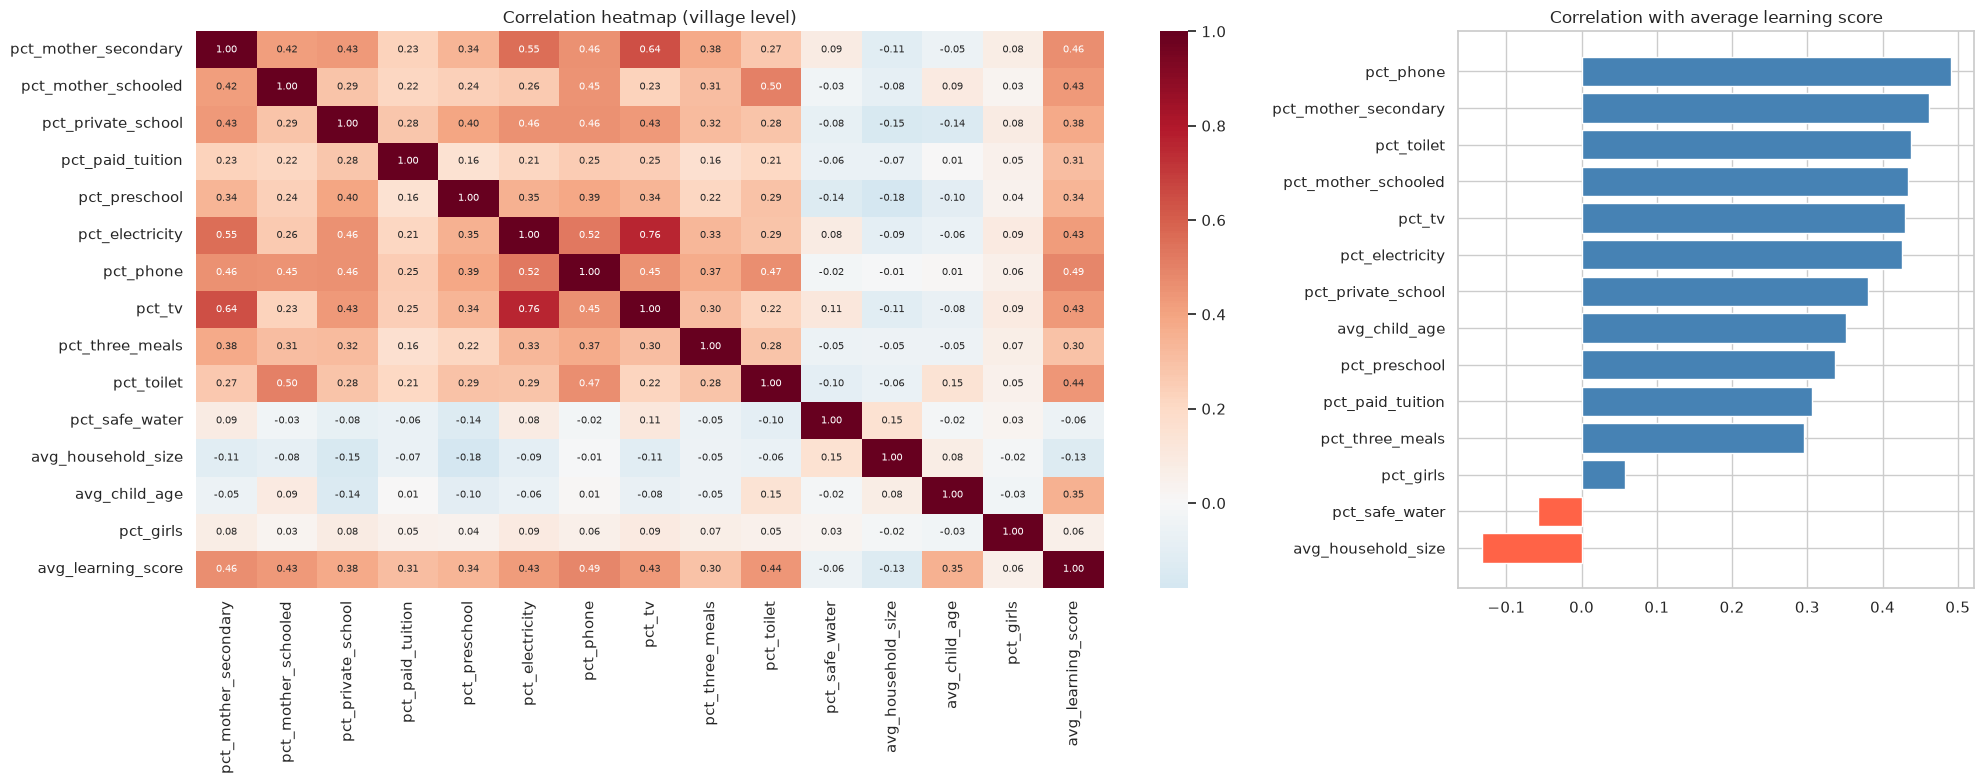

In [5]:
numeric_cols = df.select_dtypes("number").drop(columns=["village_id", "tested_children"]).columns
corr = df[numeric_cols].corr()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax1)
ax1.set_title("Correlation heatmap (village level)")
target_corr = corr[TARGET].drop(TARGET).sort_values()
ax2.barh(target_corr.index, target_corr.values, color=np.where(target_corr > 0, "steelblue", "tomato"))
ax2.set_title("Correlation with average learning score")
plt.tight_layout()
plt.show()

Phone ownership (r = 0.49), mothers' secondary education (0.46), toilets (0.44) and electricity (0.43) are the variables most strongly linked to learning. Several welfare indicators are also strongly linked to each other, such as TV and electricity (0.76), so I dropped `pct_tv` and `pct_mother_schooled` to avoid repeating the same information. I also dropped `pct_safe_water` and `pct_girls`, whose correlations with the target are close to zero.

### 2.2 Distributions of key variables

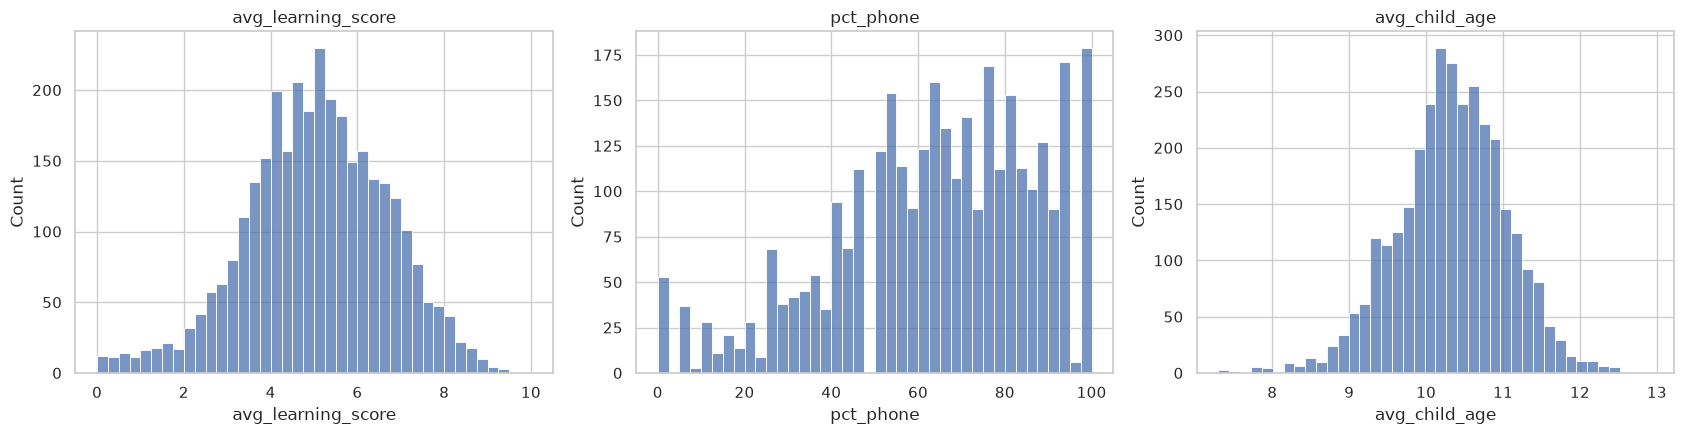

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, [TARGET, "pct_phone", "avg_child_age"]):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

The target is roughly bell-shaped around 5, with a longer tail of low-scoring villages and no extreme outliers, which suits a linear model. Phone ownership covers the full 0 to 100% range, while average child age mostly sits between 9 and 12. Because the features are on very different scales (percentages, people per household, years), I standardise them before training.

### 2.3 Mothers' education, area and region

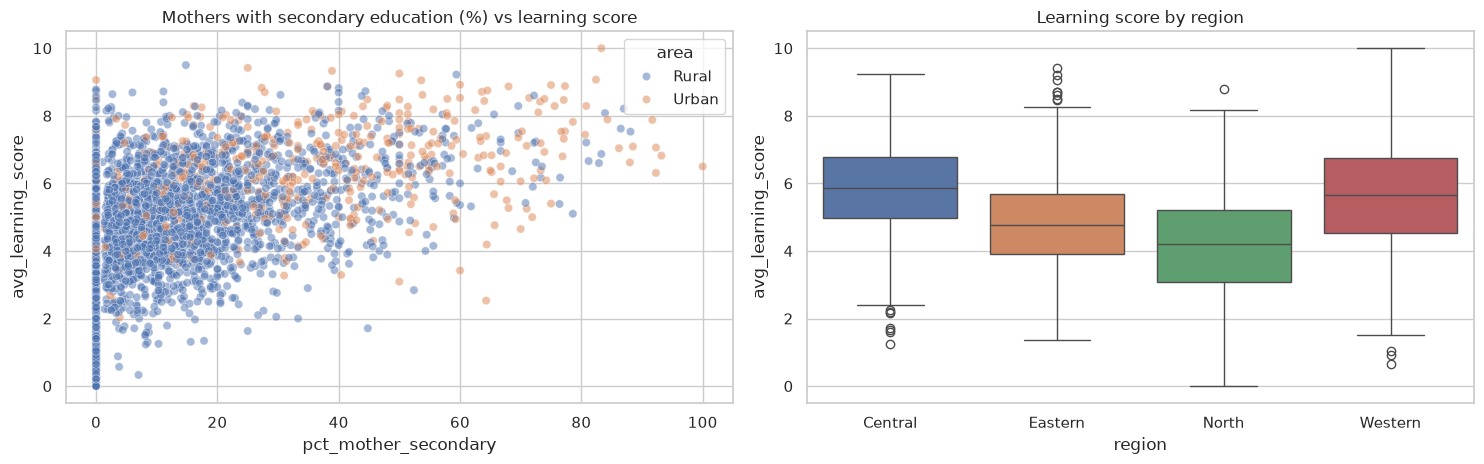

region
Central    5.86
Eastern    4.87
North      4.09
Western    5.63
Name: avg_learning_score, dtype: float64

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
sns.scatterplot(data=df, x="pct_mother_secondary", y=TARGET, hue="area", alpha=0.5, ax=ax1)
ax1.set_title("Mothers with secondary education (%) vs learning score")
sns.boxplot(data=df, x="region", y=TARGET, hue="region", legend=False, ax=ax2)
ax2.set_title("Learning score by region")
plt.tight_layout()
plt.show()
df.groupby("region")[TARGET].mean().round(2)

Villages where more mothers finished secondary school score higher, and urban villages cluster at the top of both measures. Region matters too: Central (5.86) and Western (5.63) villages score well above Eastern (4.87) and Northern (4.09) ones. I keep region and area as features because they capture differences the household measures alone do not explain.

---
## 3. Feature engineering
I use **12 features**:
- **Categorical (2):** `region`, `area` (rural or urban)
- **Numeric (10):** % of mothers with secondary education, % of children in private school, with paid tuition, and who attended preschool; % of households with electricity, a phone, a toilet, and three meals a day; average household size; average child age

**Columns I removed, and why:**
| Column | Reason |
|---|---|
| `village_id`, `district` | Identifiers. District has 112 categories, and region already captures the main geographic pattern. |
| `tested_children` | Describes the survey sample, not the village. |
| `pct_tv`, `pct_mother_schooled` | Strongly overlap with electricity and mothers' secondary education. |
| `pct_safe_water`, `pct_girls` | Almost no relationship with the target (abs(r) < 0.07). |

In [8]:
CATEGORICAL = ["region", "area"]
NUMERIC = ["pct_mother_secondary", "pct_private_school", "pct_paid_tuition", "pct_preschool",
           "pct_electricity", "pct_phone", "pct_toilet", "pct_three_meals",
           "avg_household_size", "avg_child_age"]
FEATURES = CATEGORICAL + NUMERIC

dropped = [c for c in df.columns if c not in FEATURES + [TARGET]]
print("dropped:", dropped)
df[NUMERIC + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(2)

dropped: ['village_id', 'district', 'pct_mother_schooled', 'pct_tv', 'pct_safe_water', 'tested_children', 'pct_girls']


pct_phone               0.49
pct_mother_secondary    0.46
pct_toilet              0.44
pct_electricity         0.43
pct_private_school      0.38
avg_child_age           0.35
pct_preschool           0.34
pct_paid_tuition        0.31
pct_three_meals         0.30
avg_household_size     -0.13
Name: avg_learning_score, dtype: float64

Phone ownership and mothers' secondary education are the strongest single predictors. Larger households are linked to slightly lower scores (r = -0.13).

---
## 4. Encoding, splitting and scaling
`region` and `area` are labels rather than quantities, so I one-hot encode them. I split the data 80/20, then fill missing values with the training median and standardise the numeric features. Both steps are fitted on the training set only, so no information from the test set leaks into training.

In [9]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# region and area are labels, so they are one-hot encoded; numeric gaps are filled with the training median
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
])
X_train_s = preprocessor.fit_transform(X_train)  # fit on train only
X_test_s = preprocessor.transform(X_test)
X_train_s.shape, X_test_s.shape

((2575, 16), (644, 16))

---
## 5. Model 1: linear regression with gradient descent (SGDRegressor)
### 5.1 Hyperparameter tuning
I train `SGDRegressor` one epoch at a time with `partial_fit`, so I can record the loss after every epoch. To tune it, I set aside 20% of the training data as a validation set and tried four learning rates, four regularisation strengths and five epoch counts. Each setting is scored on the average of its last five epochs, because single epochs are noisy.

In [10]:
# validation set taken from the training data, so tuning never sees the test set
X_tr, X_val, y_tr, y_val = train_test_split(X_train_s, y_train, test_size=0.2, random_state=SEED)


def train_sgd(X_a, y_a, X_b, y_b, eta0, alpha, epochs):
    model = SGDRegressor(eta0=eta0, alpha=alpha, random_state=SEED)
    rng = np.random.default_rng(SEED)
    loss_a, loss_b = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(X_a))  # reshuffle every epoch
        model.partial_fit(X_a[idx], y_a.values[idx])
        loss_a.append(mean_squared_error(y_a, model.predict(X_a)))
        loss_b.append(mean_squared_error(y_b, model.predict(X_b)))
    return model, loss_a, loss_b


lrs = [0.0001, 0.001, 0.01, 0.05]
alphas = [0.0001, 0.01, 0.1, 1.0]
epoch_options = [5, 20, 50, 100, 150]

curves, rows = {}, []
for lr in lrs:
    for alpha in alphas:
        _, _, val_loss = train_sgd(X_tr, y_tr, X_val, y_val, lr, alpha, 150)
        curves[(lr, alpha)] = val_loss
        for ep in epoch_options:
            # average of the last 5 epochs, because single epochs are noisy
            rows.append([lr, alpha, ep, np.mean(val_loss[ep - 5:ep])])

tuning = pd.DataFrame(rows, columns=["eta0", "alpha", "epochs", "val_mse"]).sort_values("val_mse")
tuning.head(10).round(4)

,eta0,alpha,epochs,val_mse
42,0.01,0.0001,50,1.2039
44,0.01,0.0001,150,1.2058
43,0.01,0.0001,100,1.2073
47,0.01,0.0100,50,1.2080
49,0.01,0.0100,150,1.2088
64,0.05,0.0001,150,1.2099
48,0.01,0.0100,100,1.2108
69,0.05,0.0100,150,1.2113
62,0.05,0.0001,50,1.2134
41,0.01,0.0001,20,1.2135


### 5.2 How each hyperparameter changes the loss

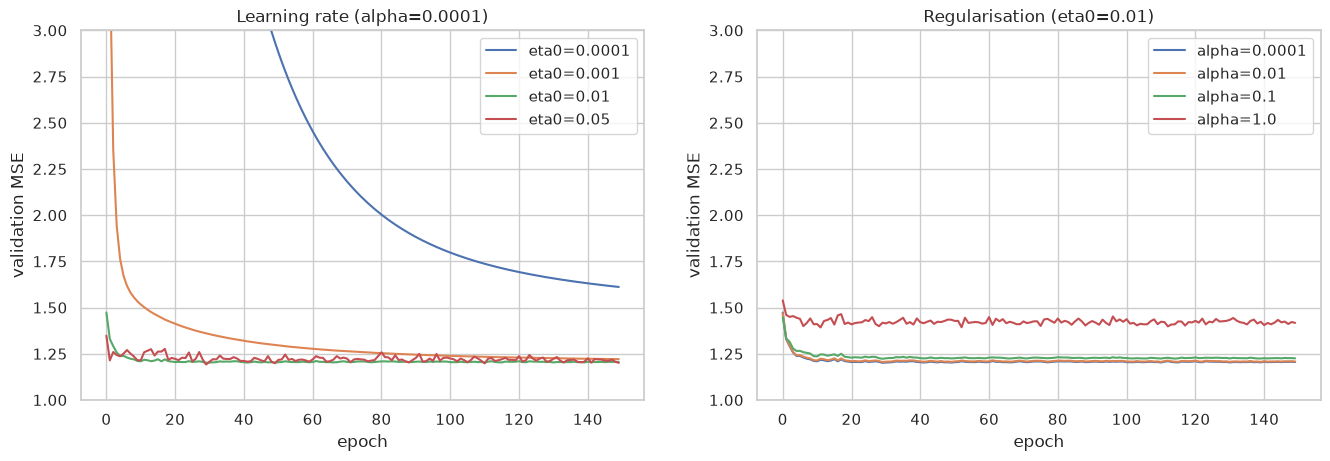

best: 0.01 0.0001 50


In [11]:
best_lr, best_alpha, best_epochs = tuning.iloc[0][["eta0", "alpha", "epochs"]]
best_epochs = int(best_epochs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8))
for lr in lrs:
    ax1.plot(curves[(lr, best_alpha)], label=f"eta0={lr}")
for alpha in alphas:
    ax2.plot(curves[(best_lr, alpha)], label=f"alpha={alpha}")
ax1.set(title=f"Learning rate (alpha={best_alpha})", xlabel="epoch", ylabel="validation MSE", ylim=(1.0, 3.0))
ax2.set(title=f"Regularisation (eta0={best_lr})", xlabel="epoch", ylabel="validation MSE", ylim=(1.0, 3.0))
ax1.legend()
ax2.legend()
plt.show()
print("best:", best_lr, best_alpha, best_epochs)

A learning rate of 0.0001 is far too slow, with validation MSE still around 1.6 after 150 epochs, while 0.001 needs about 80 epochs. 0.01 converges within a few epochs and stays stable; 0.05 converges but bounces around. Alpha makes little difference up to 0.1 (about 1.21 to 1.23), but 1.0 holds the weights back too much and raises the error to about 1.42. **Chosen settings:** eta0 = 0.01, alpha = 0.0001, 50 epochs.

### 5.3 Loss curve (train and test MSE per epoch)

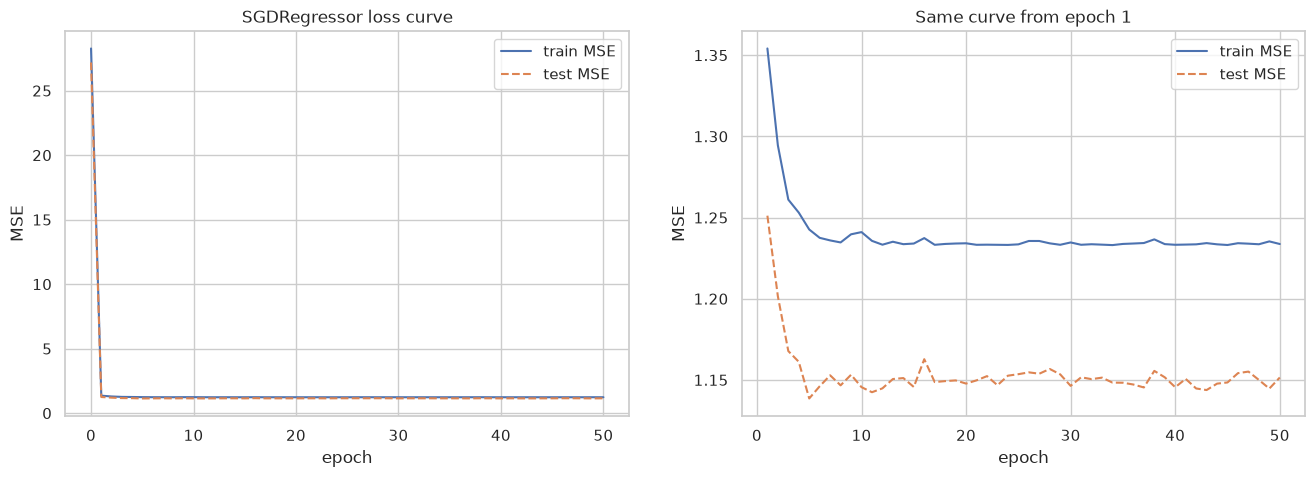

epoch 0: 28.27 / 27.18
epoch 1: 1.354 / 1.251
epoch 50: 1.234 / 1.151


In [12]:
sgd, train_loss, test_loss = train_sgd(X_train_s, y_train, X_test_s, y_test, best_lr, best_alpha, best_epochs)

# epoch 0 = untrained model (all weights 0, so it predicts 0)
train_loss = [mean_squared_error(y_train, np.zeros(len(y_train)))] + train_loss
test_loss = [mean_squared_error(y_test, np.zeros(len(y_test)))] + test_loss

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
for ax, start in [(ax1, 0), (ax2, 1)]:
    ax.plot(range(start, best_epochs + 1), train_loss[start:], label="train MSE")
    ax.plot(range(start, best_epochs + 1), test_loss[start:], "--", label="test MSE")
    ax.set(xlabel="epoch", ylabel="MSE")
    ax.legend()
ax1.set_title("SGDRegressor loss curve")
ax2.set_title("Same curve from epoch 1")
plt.show()
print(f"epoch 0: {train_loss[0]:.2f} / {test_loss[0]:.2f}")
print(f"epoch 1: {train_loss[1]:.3f} / {test_loss[1]:.3f}")
print(f"epoch {best_epochs}: {train_loss[-1]:.3f} / {test_loss[-1]:.3f}")

Before training, the model predicts 0 for every village, so the MSE starts at about 28. After one epoch it drops to 1.35 on the training set, and it settles around 1.23 by epoch 10. The test MSE stays slightly lower (about 1.15), which is just a feature of this particular split; the two curves stay close and flat, so the model is not overfitting.

---
## 6. Models 2 to 4: closed-form linear regression, decision tree, random forest
I chose the decision tree's depth and the random forest's minimum leaf size using the same validation set as above.

In [13]:
lin = LinearRegression().fit(X_train_s, y_train)


def val_mse(model):
    model.fit(X_tr, y_tr)
    return mean_squared_error(y_val, model.predict(X_val))


depth_scores = {d: val_mse(DecisionTreeRegressor(max_depth=d, random_state=SEED)) for d in [2, 3, 4, 5, 6, 8, None]}
leaf_scores = {l: val_mse(RandomForestRegressor(200, min_samples_leaf=l, random_state=SEED, n_jobs=-1)) for l in [1, 5, 10, 20]}
print("tree max_depth:", {k: round(v, 3) for k, v in depth_scores.items()})
print("forest min_samples_leaf:", {k: round(v, 3) for k, v in leaf_scores.items()})

best_depth = min(depth_scores, key=depth_scores.get)
best_leaf = min(leaf_scores, key=leaf_scores.get)
tree = DecisionTreeRegressor(max_depth=best_depth, random_state=SEED).fit(X_train_s, y_train)
forest = RandomForestRegressor(300, min_samples_leaf=best_leaf, random_state=SEED, n_jobs=-1).fit(X_train_s, y_train)

tree max_depth: {2: 1.925, 3: 1.817, 4: 1.68, 5: 1.68, 6: 1.659, 8: 2.001, None: 2.937}
forest min_samples_leaf: {1: 1.323, 5: 1.301, 10: 1.292, 20: 1.301}


The decision tree is very sensitive to depth: its validation MSE is 1.66 at depth 6 but jumps to 2.94 with no limit, a clear sign of overfitting. The random forest is steadier (1.29 to 1.32) and works best with at least 10 samples per leaf.

---
## 7. Comparing the models and choosing the best

In [14]:
models = {"SGDRegressor": sgd, "LinearRegression": lin, "DecisionTree": tree, "RandomForest": forest}
results = pd.DataFrame(
    [[mean_squared_error(y_train, m.predict(X_train_s)), mean_squared_error(y_test, m.predict(X_test_s))] for m in models.values()],
    index=models.keys(), columns=["train_mse", "test_mse"],
).sort_values("test_mse")
best_name = results.index[0]
print("baseline test MSE (always predict the training mean):", round(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())), 3))
print("best model:", best_name)
results.round(4)

baseline test MSE (always predict the training mean): 2.424
best model: LinearRegression


,train_mse,test_mse
LinearRegression,1.2327,1.1493
SGDRegressor,1.2337,1.1515
RandomForest,0.8104,1.1699
DecisionTree,1.2116,1.5970


**Best model: LinearRegression, with a test MSE of 1.149.** I chose it because it has the lowest MSE on the shared test set. Its average error is about 1.07 points on the 0 to 10 scale, compared with 2.42 for simply guessing the average.

**How the data shaped each model's results:**
- **LinearRegression (1.149) and SGDRegressor (1.152)** are almost identical, because gradient descent converges to the same least-squares solution that the closed form calculates directly. Village averages change smoothly with the community measures, so a straight-line relationship fits well.
- **The random forest (1.170)** fits the training data much more closely (0.81) but does no better on new villages, so its extra flexibility is picking up noise.
- **The decision tree (1.597)** does worst, because a single tree chops continuous percentages into coarse steps.

Linear regression is also the most useful choice for this problem: its coefficients show education officers which factors matter and in which direction, which makes the predictions easier to trust and explain.

### What drives the predictions

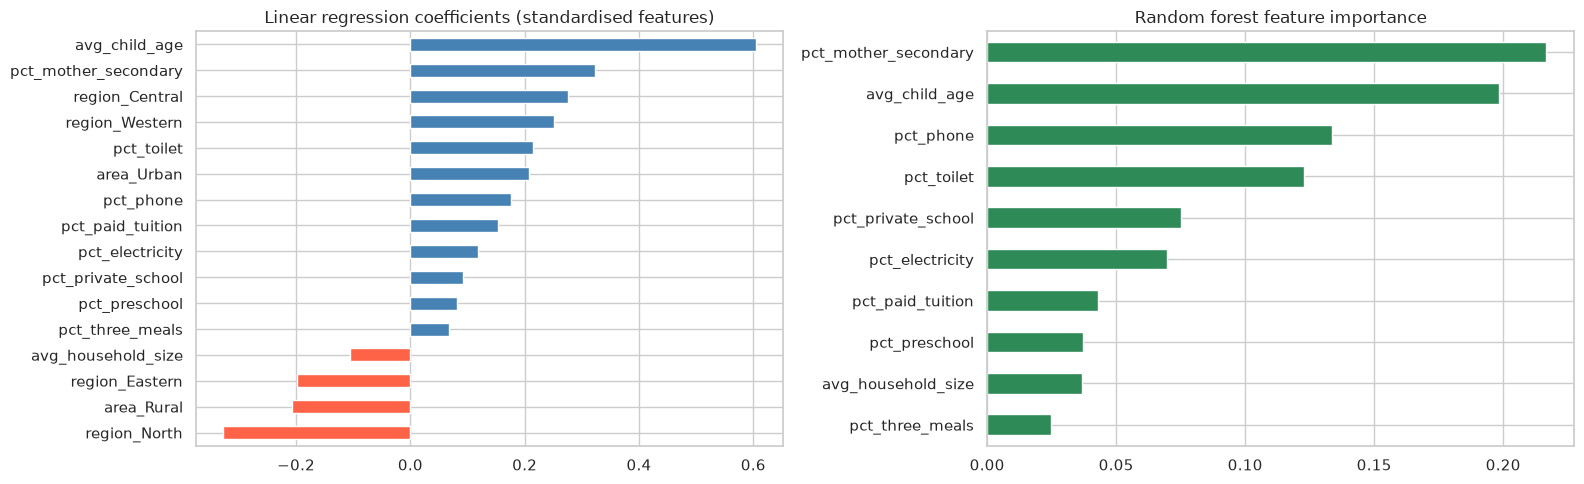

In [15]:
names = [n.split("__")[1] for n in preprocessor.get_feature_names_out()]
coefs = pd.Series(lin.coef_, index=names).sort_values()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
coefs.plot.barh(ax=ax1, color=np.where(coefs > 0, "steelblue", "tomato"))
ax1.set_title("Linear regression coefficients (standardised features)")
pd.Series(forest.feature_importances_, index=names).nlargest(10).sort_values().plot.barh(ax=ax2, color="seagreen")
ax2.set_title("Random forest feature importance")
plt.tight_layout()
plt.show()

Both models put mothers' secondary education, phone ownership and toilets near the top, along with average child age. The large age coefficient is a limitation of my target: the score is not adjusted for age, so villages whose tested children are older naturally score higher. Being rural, or in the Northern or Eastern region, lowers the predicted score even after accounting for the other factors.

---
## 8. The strongest predictor: before and after fitting a line
### Before fitting

pct_phone


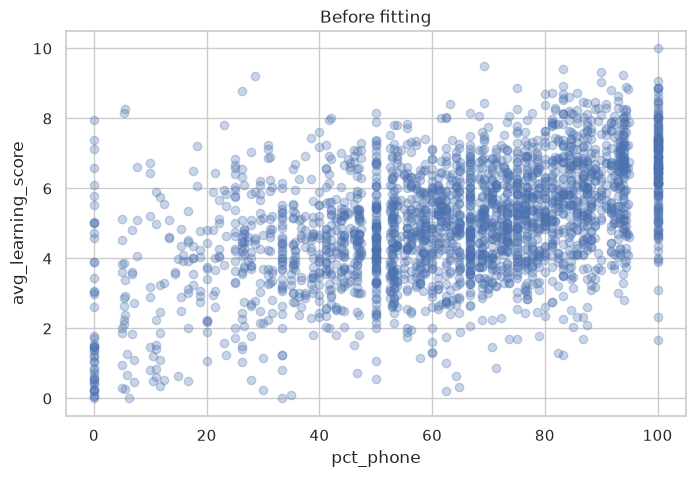

In [16]:
top = df[NUMERIC].corrwith(df[TARGET]).abs().idxmax()
print(top)
plt.figure(figsize=(8, 5))
plt.scatter(X_train[top], y_train, alpha=0.3)
plt.xlabel(top)
plt.ylabel(TARGET)
plt.title("Before fitting")
plt.show()

### After fitting
The same data with a line from a one-feature linear regression, fitted only for this plot.

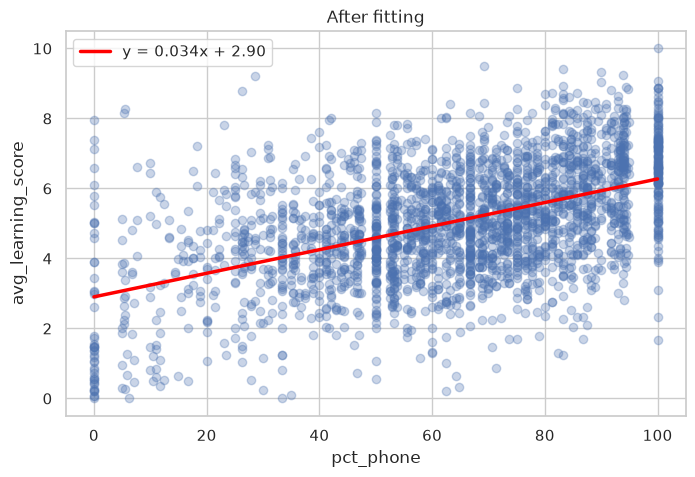

one-feature test MSE: 1.824


In [17]:
line = LinearRegression().fit(X_train[[top]], y_train)
xs = pd.DataFrame({top: np.linspace(0, 100, 50)})

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top], y_train, alpha=0.3)
plt.plot(xs[top], line.predict(xs), color="red", linewidth=2.5,
         label=f"y = {line.coef_[0]:.3f}x + {line.intercept_:.2f}")
plt.xlabel(top)
plt.ylabel(TARGET)
plt.title("After fitting")
plt.legend()
plt.show()
print("one-feature test MSE:", round(mean_squared_error(y_test, line.predict(X_test[[top]])), 3))

The slope of 0.034 means every 10 extra percentage points of phone ownership go with a score about 0.34 points higher, or roughly 3.4 points from 0% to 100%. On its own, this line has a test MSE of 1.82, much worse than the full model's 1.15. Learning depends on several community factors at once, not on any single one.

---
## 9. Saving the best model
I save the one-hot encoder, the median imputer, the scaler and the linear regression model together as one scikit-learn `Pipeline` with joblib, so the API can take raw input values. I also save the training data, because the API's `/retrain` endpoint combines it with newly uploaded villages.

In [18]:
os.makedirs("../API", exist_ok=True)  # the API folder sits next to this notebook's folder
best_model = Pipeline([("preprocess", preprocessor), ("model", models[best_name])])
joblib.dump(best_model, "../API/best_model.pkl")

# /retrain in the API refits on this data plus the uploaded rows
df[FEATURES + [TARGET]].to_csv("../API/training_data.csv", index=False)

---
## 10. Predicting one village from the test set
This function loads the saved pipeline and predicts the score for one row of the test set. The API uses the same logic.

In [19]:
def predict_one(row, path="../API/best_model.pkl"):
    model = joblib.load(path)
    return model.predict(row[FEATURES])[0]


row = X_test.iloc[[0]]
display(row)
print("predicted:", round(predict_one(row), 2))
print("actual:   ", y_test.iloc[0])

,region,area,pct_mother_secondary,pct_private_school,pct_paid_tuition,pct_preschool,pct_electricity,pct_phone,pct_toilet,pct_three_meals,avg_household_size,avg_child_age
298,Central,Rural,7.4,25.0,0.0,5.6,0.0,87.5,81.2,31.2,6.88,10.67


predicted: 5.21
actual:    6.42


For this rural village in the Central region, the model predicts 5.21 against an actual score of 6.42. The error of 1.2 points is close to the model's average error. It reflects the roughly half of the variation that depends on things this data does not capture, such as teaching quality and school resources.

---
## 11. Summary and limitations
**Summary.** Using 12 community features for 3,219 Ugandan villages, linear regression predicts the average learning score with a test MSE of 1.149, about half the error of guessing the average. Mothers' education, household phone ownership, sanitation and region are the strongest signals. That gives education officers a practical way to decide which villages need learning support first.

**Limitations.**
- The target is built from test levels and is not adjusted for age.
- Predictions describe villages, not individual children; a village with a good average can still have children who are struggling.
- School-level factors (teachers, class sizes, books) are not in the data, which limits accuracy.
- The data is from 2015, the most recent open Uwezo Uganda release.

**Next steps.** Add school data, adjust the score for age, and retrain through the API's `/retrain` endpoint as new Uwezo rounds are released.